In [7]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)

from forestgap import with_sparse_proximity

In [8]:
# Create simualted data with anomalies

np.random.seed(444)

n = 1000
t = np.arange(n)

signal = (
    np.sin(2*np.pi*t/75)
    + 0.5*np.sin(2*np.pi*t/20)
    + np.random.normal(0, 0.2, n)
)

# Ground truth labels
true_anomaly = np.zeros(n, dtype=int)

intervals = [
    (150,190),
    (420,455),
    (700,760)
]

for start, end in intervals:

    # Mark these points as true anomalies
    true_anomaly[start:end] = 1

    # Inject anomalous behavior
    signal[start:end] += np.random.normal(4,0.5,end-start)
    signal[start:end] += np.random.normal(0,0.8,end-start)

In [9]:
# Create intervals and sort internally

window_size = 30
step = 5

windows = []
window_starts = []

for start in range(0, n-window_size+1, step):

    # Extract a consecutive interval
    window = signal[start:start+window_size]

    # Sort values within that interval
    # window = np.sort(window)

    windows.append(window)
    window_starts.append(start)

X = np.array(windows)

print(X.shape)

(195, 30)


In [10]:
# Fit isolation forest and make preddictions    

ProxIsoForest = with_sparse_proximity(IsolationForest)

model = ProxIsoForest(
    n_estimators=200,
    contamination='auto',
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    prox_method='oob',
    max_features=5,
 )

model.fit(X)
print('Model fitted.')

# Window-level predictions
window_pred = model.predict(X)

# Isolation Forest returns:
#  1  -> normal
# -1  -> anomaly
window_anomaly = (window_pred == -1)

# Map window predictions back to time points    

point_score = np.zeros(len(signal))

for anomaly, start in zip(window_anomaly, window_starts):

    if anomaly:
        point_score[start:start + window_size] += 1


vote_threshold = 3

point_prediction = point_score >= vote_threshold

Model fitted.


In [11]:
# Prediction metrics

tp = (point_prediction == 1) & (true_anomaly == 1)
fp = (point_prediction == 1) & (true_anomaly == 0)
fn = (point_prediction == 0) & (true_anomaly == 1)

TP = tp.sum()
FP = fp.sum()
FN = fn.sum()

precision = TP / (TP + FP) if (TP + FP) else 0
recall = TP / (TP + FN) if (TP + FN) else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall)
    else 0
)

print("\nPerformance")
print("-------------------------")
print(f"True Positives : {TP}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"Precision      : {precision:.3f}")
print(f"Recall         : {recall:.3f}")
print(f"F1 Score       : {f1:.3f}")



Performance
-------------------------
True Positives : 135
False Positives: 85
False Negatives: 0
Precision      : 0.614
Recall         : 1.000
F1 Score       : 0.761


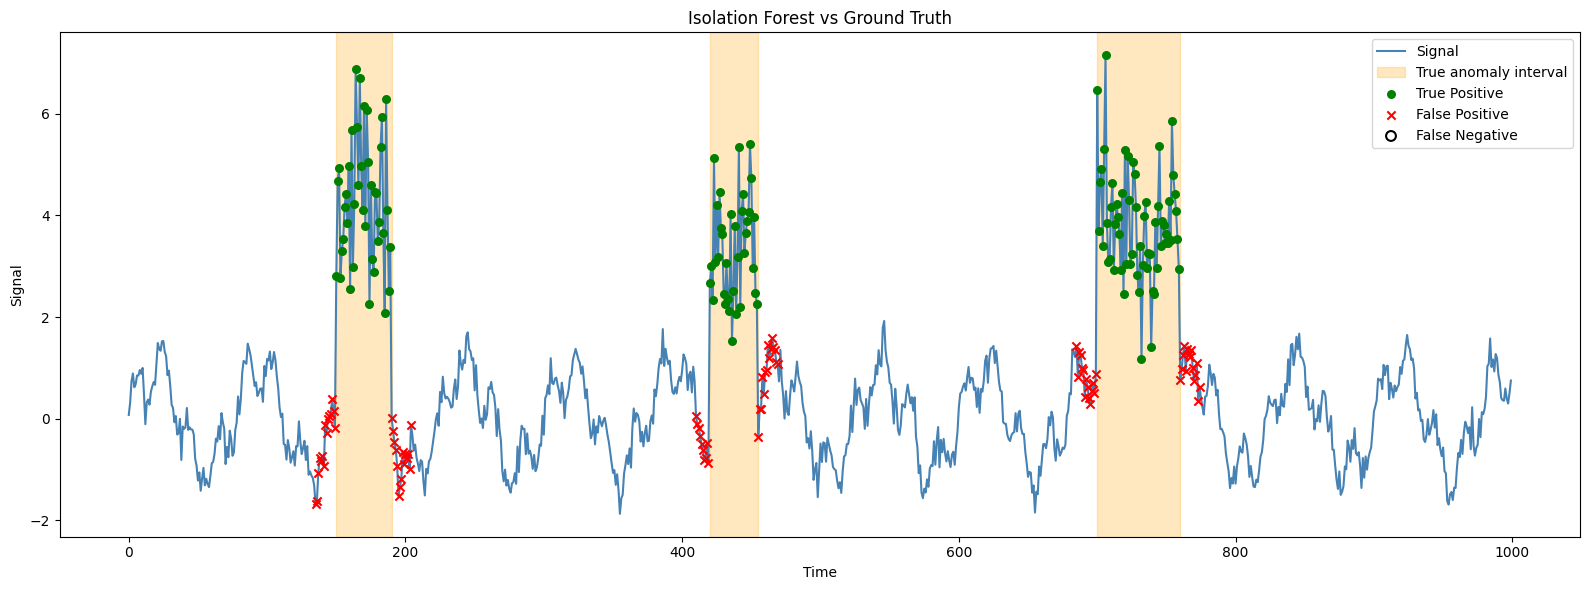

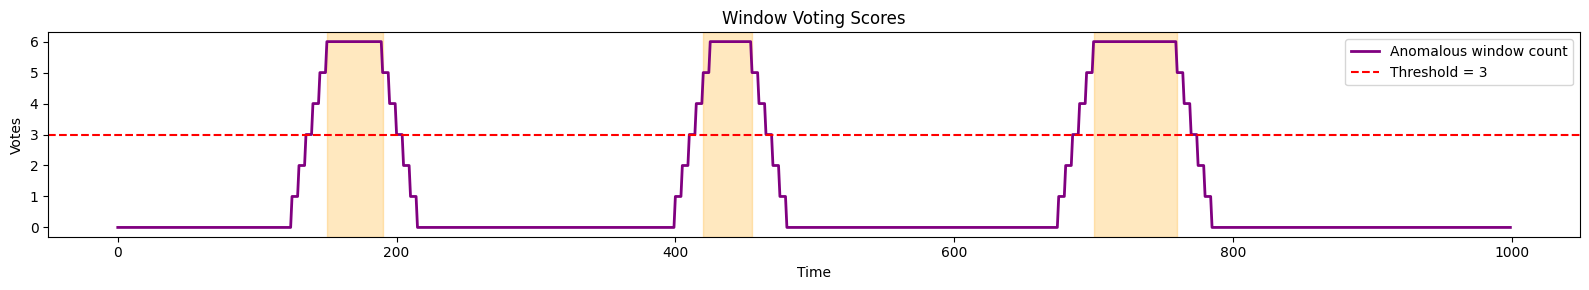

In [12]:
 # Visualization 1: Detection Results

fig, ax = plt.subplots(figsize=(16,6))

# Plot original signal
ax.plot(signal, color="steelblue", linewidth=1.5, label="Signal")

# Shade true anomaly intervals
for i, (start, end) in enumerate(intervals):
    ax.axvspan(
        start,
        end,
        color="orange",
        alpha=0.25,
        label="True anomaly interval" if i == 0 else None,
    )

# Correct detections
ax.scatter(
    np.where(tp)[0],
    signal[tp],
    color="green",
    s=30,
    label="True Positive",
    zorder=5,
)

# False positives
ax.scatter(
    np.where(fp)[0],
    signal[fp],
    color="red",
    marker="x",
    s=35,
    label="False Positive",
    zorder=5,
)

# False negatives
ax.scatter(
    np.where(fn)[0],
    signal[fn],
    facecolors="none",
    edgecolors="black",
    linewidth=1.5,
    s=50,
    label="False Negative",
    zorder=5,
)

ax.set_title("Isolation Forest vs Ground Truth")
ax.set_xlabel("Time")
ax.set_ylabel("Signal")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Visualization 2: Window Vote Counts

fig, ax = plt.subplots(figsize=(16,3))

ax.plot(
    point_score,
    color="purple",
    linewidth=2,
    label="Anomalous window count"
)

ax.axhline(
    vote_threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {vote_threshold}"
)

for i, (start, end) in enumerate(intervals):
    ax.axvspan(
        start,
        end,
        color="orange",
        alpha=0.25,
    )

ax.set_title("Window Voting Scores")
ax.set_xlabel("Time")
ax.set_ylabel("Votes")
ax.legend()

plt.tight_layout()
plt.show()